# Assignment 2 - Part 1

#### SYDE 671 - Dimitrios Christopoulos

### Part 1.1

In [ ]:
from functions import *

In [2]:
img_path = '1.1/images/dim_img_a2.jpg'

np_img = np.array(cv.imread(img_path, cv.IMREAD_GRAYSCALE))

In [3]:
np_kernel_9 = np.ones((9, 9)) / 81
np_kernel_18 = np.ones((19, 19)) / (19*19)

d_x = np.array([[1, 0, -1]])
d_y = np.array([[1], [0], [-1]])

##### Unoptimized Convolution Implementation (4 for loops)

In [10]:
convolved_image = convolve_image(np_img, np_kernel_18)

show_img(np.clip(convolved_image, 0, 255).astype(np.uint8), "Convolved Implementation Result - 18")
save_img(convolved_image, 'images/convolution_implemented_result_18')

KeyboardInterrupt: 

In [4]:
d_x_img = convolve_image(np_img, d_x)
save_img(d_x_img, 'images/conv_imp_res_d_x')

In [5]:
d_y_img = convolve_image(np_img, d_y)
save_img(d_y_img, 'images/conv_imp_res_d_y')

b##### Optimized (2 for loops)

In [4]:
convolved_image = convolve_image_opt(np_img, np_kernel_9)

save_img(convolved_image, '1.1/results/opt_conv_imp_res_9')

In [5]:
convolved_image = convolve_image_opt(np_img, np_kernel_18)

save_img(convolved_image, '1.1/results/opt_conv_imp_res_18')

In [6]:
d_x_img = convolve_image(np_img, d_x)
save_img(d_x_img, '1.1/results/opt_conv_imp_res_d_x')

In [7]:
d_y_img = convolve_image(np_img, d_y)
save_img(d_y_img, '1.1/results/opt_conv_imp_res_d_y')

##### Comparing with Scipy implementation

In [6]:
scipy_convolved_image = scipy.signal.convolve2d(np_img, np_kernel_9)
save_img(scipy_convolved_image, 'images/convolution_scipy_9')

In [7]:
scipy_convolved_image = scipy.signal.convolve2d(np_img, np_kernel_18)
save_img(scipy_convolved_image, 'images/convolution_scipy_18')

In [8]:
scipy_conv_d_x = scipy.signal.convolve2d(np_img, d_x)
save_img(scipy_conv_d_x, 'images/scipy_res_d_x')

In [9]:
scipy_conv_d_y = scipy.signal.convolve2d(np_img, d_y)
save_img(scipy_conv_d_y, 'images/scipy_res_d_y')

### Part 1.2

In [1]:
from functions import *

In [2]:
img_path = '1.2/images/cameraman_img.png'

np_img = np.array(cv.imread(img_path, cv.IMREAD_GRAYSCALE))

In [3]:
d_x = np.array([[1, 0, -1]])
d_y = np.array([[1], [0], [-1]])

In [4]:
camera_img_x = scipy.signal.convolve2d(np_img, d_x, mode='same')
save_img(camera_img_x, '1.2/results/cameraman_dx')

camera_img_y = scipy.signal.convolve2d(np_img, d_y, mode='same')
save_img(camera_img_y, '1.2/results/cameraman_dy')

In [5]:
img_grad_mag = compute_grad_mag(camera_img_x, camera_img_y)
save_img(img_grad_mag, '1.2/results/cameraman_grad_mag')

In [6]:
for i in range(5):
    threshold_img = img_grad_mag.copy()
    threshold_img[img_grad_mag < (i+1) * 0.1 * 255] = 0

    save_img(threshold_img, f'1.2/results/threshold_grad_{(i+1)*10}%')

In [7]:
threshold_img = img_grad_mag.copy()
threshold_img[img_grad_mag < (1.5) * 0.1 * 255] = 0

save_img(threshold_img, f'1.2/results/threshold_grad_15%')

### Part 1.3

In [8]:
one_d_gauss = cv.getGaussianKernel(ksize=9, sigma=0)
two_d_gauss = one_d_gauss * one_d_gauss.T

In [9]:
np_img_blur = scipy.signal.convolve2d(np_img, two_d_gauss, mode='same')
save_img(np_img_blur, '1.3/results/cameraman_blurred')

In [10]:
camera_img_x = scipy.signal.convolve2d(np_img_blur, d_x, mode='same')
save_img(camera_img_x, '1.3/results/blur_cameraman_dx')

camera_img_y = scipy.signal.convolve2d(np_img_blur, d_y, mode='same')
save_img(camera_img_y, '1.3/results/blur_cameraman_dy')

In [11]:
img_grad_mag = compute_grad_mag(camera_img_x, camera_img_y)
save_img(img_grad_mag, '1.3/results/blur_cameraman_grad_mag')

In [12]:
for i in range(5):
    threshold_img = img_grad_mag.copy()
    threshold_img[img_grad_mag < (i+1) * 0.1 * 255] = 0

    save_img(threshold_img, f'1.3/results/threshold_grad_{(i+1)*10}%')

In [13]:
threshold_img = img_grad_mag.copy()
threshold_img[img_grad_mag < (1.5) * 0.1 * 255] = 0

save_img(threshold_img, f'1.3/results/threshold_grad_15%')

In [14]:
dx_blur = scipy.signal.convolve2d(two_d_gauss, d_x, mode='same')
dy_blur = scipy.signal.convolve2d(two_d_gauss, d_y, mode='same')

save_img(cv.normalize(dx_blur, None, 0, 255, cv.NORM_MINMAX), '1.3/results/dx_blur')
save_img(cv.normalize(dy_blur, None, 0, 255, cv.NORM_MINMAX), '1.3/results/dy_blur')

In [15]:
dog_img_x = scipy.signal.convolve2d(np_img, dx_blur, mode='same')
dog_img_y = scipy.signal.convolve2d(np_img, dy_blur, mode='same')

img_grad_mag = compute_grad_mag(dog_img_x, dog_img_y)
save_img(img_grad_mag, '1.3/results/dog_grad_mag')

In [16]:
threshold_img = img_grad_mag.copy()
threshold_img[img_grad_mag < (1.5) * 0.1 * 255] = 0

save_img(threshold_img, f'1.3/results/dog_threshold_grad_15%')

In [19]:
import matplotlib.pyplot as plt

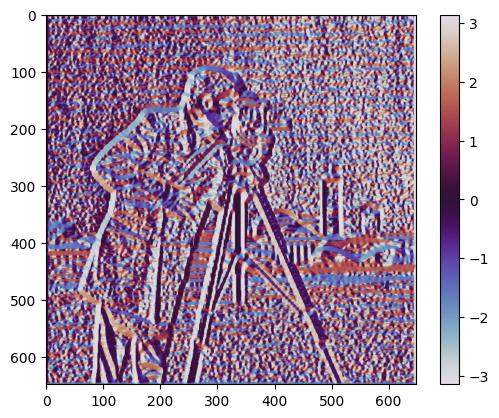

<Figure size 640x480 with 0 Axes>

In [22]:
img_orientations = np.atan2(dog_img_y, dog_img_x)

plt.imshow(img_orientations, cmap='twilight', vmin=-np.pi, vmax=np.pi)
plt.colorbar()
plt.show()

plt.savefig('1.3/results/orientations')